<a href="https://colab.research.google.com/github/mmeenakshibio2016-byte/-Drug-Response-Prediction-ML-model-to-predict-cancer-cell-line-response-to-drugs-TDC-dataset-./blob/main/PharmaQuality_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

!pip install numpy pandas matplotlib seaborn scikit-learn streamlit


In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
np.random.seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

n = 1000

data = {
    "Batch_ID": [f"BT{str(i).zfill(4)}"
                 for i in range(1, n + 1)],

    "pH": np.random.normal(7.0, 0.15, n),

    "Protein_Concentration":
        np.random.normal(100, 5, n),

    "Temperature":
        np.random.normal(25, 2, n),

    "Mixing_Time":
        np.random.normal(60, 10, n),

    "Dissolved_Oxygen":
        np.random.normal(30, 5, n),

    "Aggregation":
        np.random.normal(2.5, 0.8, n),

    "Potency":
        np.random.normal(100, 3, n)
}

df = pd.DataFrame(data)

df.head()


,Batch_ID,pH,Protein_Concentration,Temperature,Mixing_Time,Dissolved_Oxygen,Aggregation,Potency
0,BT0001,7.074507,106.996777,23.649643,40.921924,25.682532,2.160992,96.657756
1,BT0002,6.979260,104.623168,24.710963,51.396150,29.843983,2.137269,98.107207
2,BT0003,7.097153,100.298152,23.415160,55.863945,30.090084,1.063485,97.173819
3,BT0004,7.228454,96.765316,24.384077,78.876877,32.363152,2.235928,98.356013
4,BT0005,6.964877,103.491117,21.212771,65.565531,23.165708,3.086263,99.357549


In [6]:
np.random.normal(7.0, 0.15, 1000)

array([7.11777776, 6.73334786, 7.10721185, 6.96494139, 7.10611866,
       7.11653975, 7.24118726, 7.20301805, 7.20198575, 7.21655055,
       7.04370685, 7.00482776, 7.13092256, 7.10981214, 6.95364006,
       7.06072351, 6.99473553, 6.87191006, 7.19356911, 7.00827989,
       7.30730624, 6.75617616, 6.91648318, 7.00489583, 7.17060716,
       7.05992041, 7.04657091, 6.83091043, 6.82645879, 7.0483757 ,
       6.7953841 , 6.92021834, 7.0751376 , 6.85265136, 7.24080339,
       7.18359045, 6.764287  , 6.86014431, 6.65713341, 6.8826113 ,
       7.11495827, 6.93791576, 7.06911959, 6.77164985, 7.11969629,
       6.91673362, 7.00182545, 6.98606882, 6.80926772, 6.82703735,
       7.14516917, 7.05984882, 7.15750736, 7.04869874, 7.0214486 ,
       6.74109841, 6.959445  , 6.99589235, 7.29296608, 7.10304349,
       7.23040918, 7.08963066, 6.89330452, 7.01756863, 7.03543355,
       6.85912666, 6.94234189, 6.96913495, 7.24084297, 6.68788892,
       7.18087276, 6.85948071, 6.79418812, 7.17699132, 7.10978

In [7]:

df["Quality_Status"] = np.where(
    (df["pH"] < 6.7) |
    (df["pH"] > 7.3) |
    (df["Aggregation"] > 4.5) |
    (df["Potency"] < 90),
    "Fail",
    "Pass"
)

df.head()


,Batch_ID,pH,Protein_Concentration,Temperature,Mixing_Time,Dissolved_Oxygen,Aggregation,Potency,Quality_Status
0,BT0001,7.074507,106.996777,23.649643,40.921924,25.682532,2.160992,96.657756,Pass
1,BT0002,6.979260,104.623168,24.710963,51.396150,29.843983,2.137269,98.107207,Pass
2,BT0003,7.097153,100.298152,23.415160,55.863945,30.090084,1.063485,97.173819,Pass
3,BT0004,7.228454,96.765316,24.384077,78.876877,32.363152,2.235928,98.356013,Pass
4,BT0005,6.964877,103.491117,21.212771,65.565531,23.165708,3.086263,99.357549,Pass


In [8]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nQuality Status:")
print(df["Quality_Status"].value_counts())


Dataset Shape: (1000, 9)

Column Names:
['Batch_ID', 'pH', 'Protein_Concentration', 'Temperature', 'Mixing_Time', 'Dissolved_Oxygen', 'Aggregation', 'Potency', 'Quality_Status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Batch_ID               1000 non-null   object 
 1   pH                     1000 non-null   float64
 2   Protein_Concentration  1000 non-null   float64
 3   Temperature            1000 non-null   float64
 4   Mixing_Time            1000 non-null   float64
 5   Dissolved_Oxygen       1000 non-null   float64
 6   Aggregation            1000 non-null   float64
 7   Potency                1000 non-null   float64
 8   Quality_Status         1000 non-null   object 
dtypes: float64(7), object(2)
memory usage: 70.4+ KB

Statistical Summary:


,pH,Protein_Concentration,Temperature,Mixing_Time,Dissolved_Oxygen,Aggregation,Potency
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,7.002900,100.354181,25.011668,59.812808,29.753632,2.462610,99.915530
std,0.146882,4.987272,1.966909,10.271325,4.961901,0.805911,3.075013
min,6.513810,85.298057,18.960976,30.705513,14.116481,0.180389,91.862162
25%,6.902861,96.968792,23.704001,52.625795,26.586975,1.945046,97.734588
50%,7.003795,100.315386,24.999498,60.001846,29.908790,2.465738,99.835761
75%,7.097192,103.644411,26.321831,66.669454,33.195616,2.989957,102.099235
max,7.577910,115.965538,32.852475,92.430930,45.564551,4.978640,110.587166



Quality Status:
Quality_Status
Pass    949
Fail     51
Name: count, dtype: int64


In [9]:

df.to_csv("pharma_batch_data.csv", index=False)

print("Dataset exported successfully!")


Dataset exported successfully!


In [10]:
df.head(10)

,Batch_ID,pH,Protein_Concentration,Temperature,Mixing_Time,Dissolved_Oxygen,Aggregation,Potency,Quality_Status
0,BT0001,7.074507,106.996777,23.649643,40.921924,25.682532,2.160992,96.657756,Pass
1,BT0002,6.979260,104.623168,24.710963,51.396150,29.843983,2.137269,98.107207,Pass
2,BT0003,7.097153,100.298152,23.415160,55.863945,30.090084,1.063485,97.173819,Pass
3,BT0004,7.228454,96.765316,24.384077,78.876877,32.363152,2.235928,98.356013,Pass
4,BT0005,6.964877,103.491117,21.212771,65.565531,23.165708,3.086263,99.357549,Pass
5,BT0006,6.964879,101.967427,25.426587,46.645184,32.962836,1.480614,102.511463,Pass
6,BT0007,7.236882,104.475966,25.002411,64.860363,16.478042,3.338786,99.036523,Pass
7,BT0008,7.115115,103.175859,23.365823,44.526960,26.850577,2.890220,95.243123,Pass
8,BT0009,6.929579,105.247764,26.318491,70.826911,27.558631,1.912613,103.420204,Pass
9,BT0010,7.081384,97.323824,26.875140,55.288753,33.166634,2.386776,97.488730,Pass


In [11]:
df.isnull().sum()

,0
Batch_ID,0
pH,0
Protein_Concentration,0
Temperature,0
Mixing_Time,0
Dissolved_Oxygen,0
Aggregation,0
Potency,0
Quality_Status,0


In [12]:
df['Protein_Concentration'].mean()

np.float64(100.35418118624578)

In [13]:
# To get value counts of a specific column, call the .value_counts() method on it
df['Quality_Status'].value_counts()

,count
Quality_Status,
Pass,949
Fail,51


In [14]:
# Calculate the percentage of failed batches
failed_percentage = (df['Quality_Status'] == 'Fail').mean() * 100
print(f"Percentage of failed batches: {failed_percentage:.2f}%")

Percentage of failed batches: 5.10%


In [15]:
# Filter batches with high aggregation (e.g., > 3.0) and count their quality status
high_aggregation_batches = df[df['Aggregation'] > 3.0]
high_aggregation_batches['Quality_Status'].value_counts()

,count
Quality_Status,
Pass,234
Fail,13


In [16]:
# To select batches with a metric (e.g., Potency) greater than 95%
df_high_potency = df[df['Potency'] < 95]
df_high_potency.head()

,Batch_ID,pH,Protein_Concentration,Temperature,Mixing_Time,Dissolved_Oxygen,Aggregation,Potency,Quality_Status
28,BT0029,6.909904,103.067590,25.419319,54.901933,37.992691,3.530461,94.103332,Pass
37,BT0038,6.706049,92.678126,23.982073,61.704638,28.892434,1.950628,94.915080,Pass
182,BT0183,6.839366,104.591583,24.639217,48.963302,25.768201,2.339489,94.812451,Pass
194,BT0195,7.025977,92.035031,25.379412,44.649598,18.065351,1.022742,91.862162,Pass
233,BT0234,6.902260,112.898547,26.785195,79.114191,32.522416,2.294444,92.536534,Pass


In [17]:
# Create a boolean column indicating if Aggregation is greater than 3.5
df['HighAggregation>3.5'] = df['Aggregation'] > 3.5
df.head()

,Batch_ID,pH,Protein_Concentration,Temperature,Mixing_Time,Dissolved_Oxygen,Aggregation,Potency,Quality_Status,HighAggregation>3.5
0,BT0001,7.074507,106.996777,23.649643,40.921924,25.682532,2.160992,96.657756,Pass,False
1,BT0002,6.979260,104.623168,24.710963,51.396150,29.843983,2.137269,98.107207,Pass,False
2,BT0003,7.097153,100.298152,23.415160,55.863945,30.090084,1.063485,97.173819,Pass,False
3,BT0004,7.228454,96.765316,24.384077,78.876877,32.363152,2.235928,98.356013,Pass,False
4,BT0005,6.964877,103.491117,21.212771,65.565531,23.165708,3.086263,99.357549,Pass,False


In [18]:

# Create a copy so the original dataset stays safe
df_dirty = df.copy()

# Introduce missing values
df_dirty.loc[10:20, "pH"] = np.nan
df_dirty.loc[30:40, "Potency"] = np.nan

# Introduce duplicate rows
df_dirty = pd.concat(
    [df_dirty, df_dirty.iloc[0:5]],
    ignore_index=True
)

print("Original shape:", df.shape)
print("Dirty dataset shape:", df_dirty.shape)


Original shape: (1000, 10)
Dirty dataset shape: (1005, 10)


In [19]:

# Missing values per column
print(df_dirty.isnull().sum())

# Total missing values
print("Total missing values:",
      df_dirty.isnull().sum().sum())

# Percentage of missing values
missing_percentage = (
    df_dirty.isnull().mean() * 100
)

print(missing_percentage)


Batch_ID                  0
pH                       11
Protein_Concentration     0
Temperature               0
Mixing_Time               0
Dissolved_Oxygen          0
Aggregation               0
Potency                  11
Quality_Status            0
HighAggregation>3.5       0
dtype: int64
Total missing values: 22
Batch_ID                 0.000000
pH                       1.094527
Protein_Concentration    0.000000
Temperature              0.000000
Mixing_Time              0.000000
Dissolved_Oxygen         0.000000
Aggregation              0.000000
Potency                  1.094527
Quality_Status           0.000000
HighAggregation>3.5      0.000000
dtype: float64


In [20]:

df_clean = df_dirty.copy()

numerical_columns = df_clean.select_dtypes(
    include="number"
).columns

for column in numerical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

print(df_clean.isnull().sum())


Batch_ID                 0
pH                       0
Protein_Concentration    0
Temperature              0
Mixing_Time              0
Dissolved_Oxygen         0
Aggregation              0
Potency                  0
Quality_Status           0
HighAggregation>3.5      0
dtype: int64


In [21]:

print("Duplicates before cleaning:",
      df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates after cleaning:",
      df_clean.duplicated().sum())

print("Cleaned shape:", df_clean.shape)


Duplicates before cleaning: 5
Duplicates after cleaning: 0
Cleaned shape: (1000, 10)


In [22]:
# Calculate the number of missing values per row in the dirty dataset
df_dirty['count_missing_values'] = df_dirty.isnull().sum(axis=1)
df_dirty.head(15)

,Batch_ID,pH,Protein_Concentration,Temperature,Mixing_Time,Dissolved_Oxygen,Aggregation,Potency,Quality_Status,HighAggregation>3.5,count_missing_values
0,BT0001,7.074507,106.996777,23.649643,40.921924,25.682532,2.160992,96.657756,Pass,False,0
1,BT0002,6.979260,104.623168,24.710963,51.396150,29.843983,2.137269,98.107207,Pass,False,0
2,BT0003,7.097153,100.298152,23.415160,55.863945,30.090084,1.063485,97.173819,Pass,False,0
3,BT0004,7.228454,96.765316,24.384077,78.876877,32.363152,2.235928,98.356013,Pass,False,0
4,BT0005,6.964877,103.491117,21.212771,65.565531,23.165708,3.086263,99.357549,Pass,False,0
5,BT0006,6.964879,101.967427,25.426587,46.645184,32.962836,1.480614,102.511463,Pass,False,0
6,BT0007,7.236882,104.475966,25.002411,64.860363,16.478042,3.338786,99.036523,Pass,False,0
7,BT0008,7.115115,103.175859,23.365823,44.526960,26.850577,2.890220,95.243123,Pass,False,0
8,BT0009,6.929579,105.247764,26.318491,70.826911,27.558631,1.912613,103.420204,Pass,False,0
9,BT0010,7.081384,97.323824,26.875140,55.288753,33.166634,2.386776,97.488730,Pass,False,0


In [23]:
# Assign the scalar string directly so pandas can broadcast it to all 1000 rows
df['Potency'] = 'missingvalues'
df.head()

,Batch_ID,pH,Protein_Concentration,Temperature,Mixing_Time,Dissolved_Oxygen,Aggregation,Potency,Quality_Status,HighAggregation>3.5
0,BT0001,7.074507,106.996777,23.649643,40.921924,25.682532,2.160992,missingvalues,Pass,False
1,BT0002,6.979260,104.623168,24.710963,51.396150,29.843983,2.137269,missingvalues,Pass,False
2,BT0003,7.097153,100.298152,23.415160,55.863945,30.090084,1.063485,missingvalues,Pass,False
3,BT0004,7.228454,96.765316,24.384077,78.876877,32.363152,2.235928,missingvalues,Pass,False
4,BT0005,6.964877,103.491117,21.212771,65.565531,23.165708,3.086263,missingvalues,Pass,False


In [24]:
# Remove duplicate rows from the df_dirty dataset
df_no_duplicates = df_dirty.drop_duplicates()
print("Shape before removing duplicates:", df_dirty.shape)
print("Shape after removing duplicates:", df_no_duplicates.shape)

Shape before removing duplicates: (1005, 11)
Shape after removing duplicates: (1000, 11)


In [25]:
df['median_pH'] = df_dirty['pH'].median()
df.head()

,Batch_ID,pH,Protein_Concentration,Temperature,Mixing_Time,Dissolved_Oxygen,Aggregation,Potency,Quality_Status,HighAggregation>3.5,median_pH
0,BT0001,7.074507,106.996777,23.649643,40.921924,25.682532,2.160992,missingvalues,Pass,False,7.00428
1,BT0002,6.979260,104.623168,24.710963,51.396150,29.843983,2.137269,missingvalues,Pass,False,7.00428
2,BT0003,7.097153,100.298152,23.415160,55.863945,30.090084,1.063485,missingvalues,Pass,False,7.00428
3,BT0004,7.228454,96.765316,24.384077,78.876877,32.363152,2.235928,missingvalues,Pass,False,7.00428
4,BT0005,6.964877,103.491117,21.212771,65.565531,23.165708,3.086263,missingvalues,Pass,False,7.00428


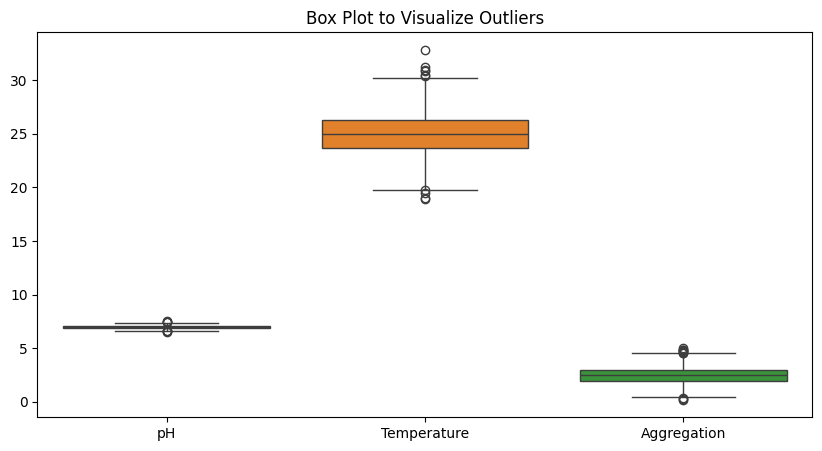

In [26]:
# The KeyError occurred because "outliers" is not a column in df.
# Let's create an actual box plot to visualize outliers in our numerical columns instead!
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[['pH', 'Temperature', 'Aggregation']])
plt.title('Box Plot to Visualize Outliers')
plt.show()

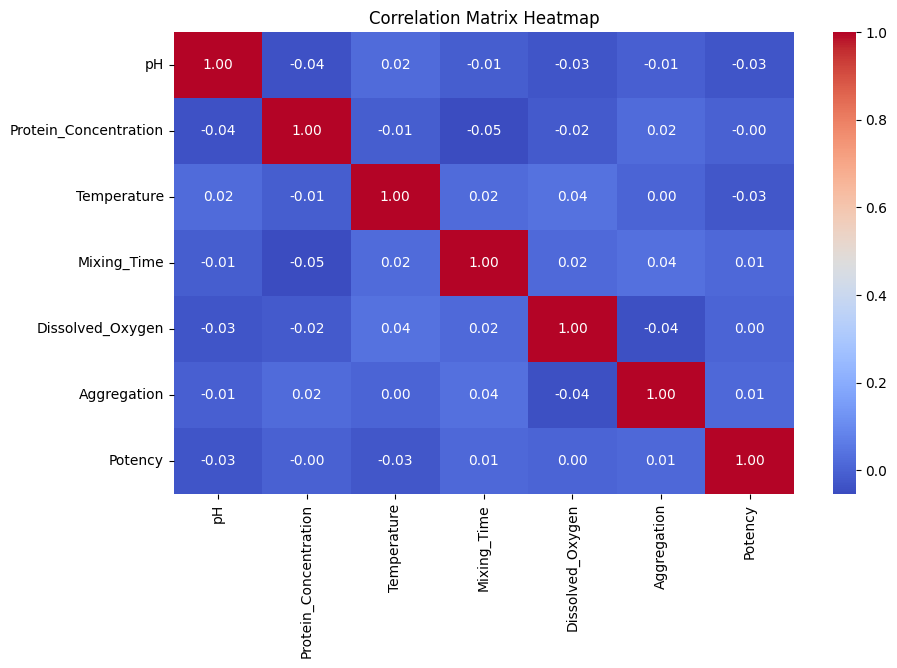

                             pH  Protein_Concentration  Temperature  \
pH                     1.000000              -0.040400     0.022129   
Protein_Concentration -0.040400               1.000000    -0.011199   
Temperature            0.022129              -0.011199     1.000000   
Mixing_Time           -0.013321              -0.054698     0.021586   
Dissolved_Oxygen      -0.031237              -0.018687     0.036015   
Aggregation           -0.005723               0.022221     0.003155   
Potency               -0.032866              -0.001289    -0.029101   

                       Mixing_Time  Dissolved_Oxygen  Aggregation   Potency  
pH                       -0.013321         -0.031237    -0.005723 -0.032866  
Protein_Concentration    -0.054698         -0.018687     0.022221 -0.001289  
Temperature               0.021586          0.036015     0.003155 -0.029101  
Mixing_Time               1.000000          0.019204     0.035692  0.011433  
Dissolved_Oxygen          0.019204       

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset since 'df' might not be in the kernel memory
try:
    df = pd.read_csv("pharma_batch_data.csv")
except FileNotFoundError:
    # Fallback to recreate df if the CSV does not exist
    n = 1000
    np.random.seed(42)
    df = pd.DataFrame({
        "pH": np.random.normal(7.0, 0.15, n),
        "Protein_Concentration": np.random.normal(100, 5, n),
        "Temperature": np.random.normal(25, 2, n),
        "Mixing_Time": np.random.normal(60, 10, n),
        "Dissolved_Oxygen": np.random.normal(30, 5, n),
        "Aggregation": np.random.normal(2.5, 0.8, n),
        "Potency": np.random.normal(100, 3, n)
    })

# Calculate correlation matrix using only available numeric columns
columns_to_correlate = [col for col in ["pH", "Protein_Concentration", "Temperature", "Mixing_Time", "Dissolved_Oxygen", "Aggregation", "Potency"] if col in df.columns]
correlation_matrix = df[columns_to_correlate].corr()

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix Heatmap")
plt.show()

print(correlation_matrix)

In [28]:
df.groupby("Quality_Status")[["Aggregation", "Potency"]].mean()

,Aggregation,Potency
Quality_Status,,
Fail,2.691271,100.111427
Pass,2.450321,99.905003


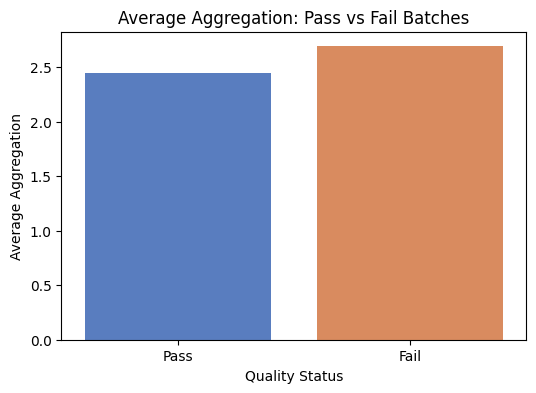

In [29]:
# Calculate and plot the average aggregation for Pass vs Fail batches without warnings
plt.figure(figsize=(6, 4))
sns.barplot(
    data=df,
    x='Quality_Status',
    y='Aggregation',
    hue='Quality_Status',
    legend=False,
    errorbar=None,
    palette='muted'
)
plt.title('Average Aggregation: Pass vs Fail Batches')
plt.xlabel('Quality Status')
plt.ylabel('Average Aggregation')
plt.show()

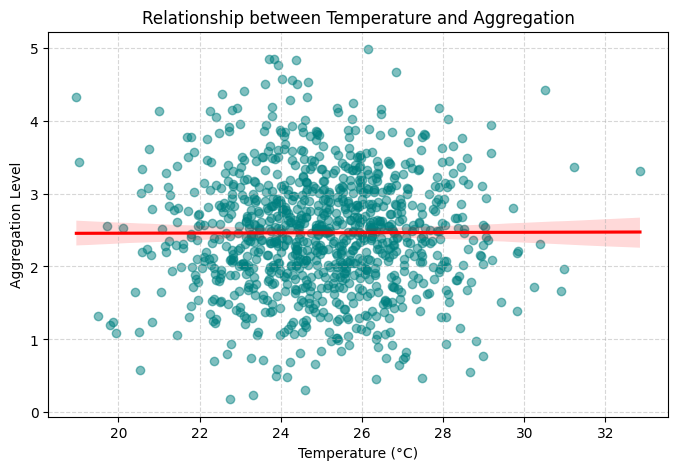

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the relationship between Temperature and Aggregation
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='Temperature', y='Aggregation', scatter_kws={'alpha':0.5, 'color':'teal'}, line_kws={'color':'red'})
plt.title('Relationship between Temperature and Aggregation')
plt.xlabel('Temperature (°C)')
plt.ylabel('Aggregation Level')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [31]:
import pandas as pd
import numpy as np
import os

# Check if file exists; if not, recreate the original dataset
if not os.path.exists('pharma_batch_data.csv'):
    print("'pharma_batch_data.csv' not found. Re-creating the synthetic dataset...")
    n = 1000
    np.random.seed(42)

    data = {
        "Batch_ID": [f"BT{str(i).zfill(4)}" for i in range(1, n + 1)],
        "pH": np.random.normal(7.0, 0.15, n),
        "Protein_Concentration": np.random.normal(100, 5, n),
        "Temperature": np.random.normal(25, 2, n),
        "Mixing_Time": np.random.normal(60, 10, n),
        "Dissolved_Oxygen": np.random.normal(30, 5, n),
        "Aggregation": np.random.normal(2.5, 0.8, n),
        "Potency": np.random.normal(100, 3, n)
    }
    df = pd.DataFrame(data)

    # Apply the logic for Quality_Status
    df["Quality_Status"] = np.where(
        (df["pH"] < 6.7) |
        (df["pH"] > 7.3) |
        (df["Aggregation"] > 4.5) |
        (df["Potency"] < 90),
        "Fail",
        "Pass"
    )

    # Save to CSV
    df.to_csv('pharma_batch_data.csv', index=False)
    print("Dataset recreated and saved successfully as 'pharma_batch_data.csv'.\n")
else:
    df = pd.read_csv('pharma_batch_data.csv')

# Show the value counts of the quality status
print(df['Quality_Status'].value_counts())

# Calculate and display the percentage of failed batches
failed_pct = (df['Quality_Status'] == 'Fail').mean() * 100
print(f"\nPercentage of failed batches: {failed_pct:.2f}%")

Quality_Status
Pass    949
Fail     51
Name: count, dtype: int64

Percentage of failed batches: 5.10%


In [32]:
from scipy.stats import ttest_ind

# Separate aggregation values into two groups
pass_aggregation = df.loc[
    df["Quality_Status"] == "Pass", "Aggregation"
]

fail_aggregation = df.loc[
    df["Quality_Status"] == "Fail", "Aggregation"
]

# Perform Welch's independent samples t-test
t_stat, p_value = ttest_ind(
    pass_aggregation,
    fail_aggregation,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -1.4066109142180385
P-value: 0.16546392504563182
